## 02 - Data preparation

This notebook implements lifecycle stage 2: data management.

The goal is to create one modelling table containing one row per household-crop combination, with the reported-loss target and selected crop, location, household, and farm characteristics.

### 1. Load the required source tables

I load the selected columns directly from the original Stata files so that this notebook can run independently.

The harvest table provides the target, initial crop-and-location predictors, household identifier, and sampling weight. The household, plot, and crop tables provide the additional characteristics selected during exploration.

The crop-level irrigation question (`s03_q05`) is excluded from this initial version because 96.33% of its source records have missing responses. Plot-level irrigation infrastructure is retained as a different measure.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Use the project root as the working directory.
DATA_DIR = Path("data/raw")

print("Working directory:", Path.cwd())

# Stop with a clear message if this kernel cannot access the project data.
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Cannot find {DATA_DIR.resolve()}. "
        "Check the working directory and selected kernel."
    )

Working directory: /Users/mac/Developer/HIS/Courses/Introduction to Data Science A1N/Assignments/nass-postharvest-project


In [2]:
# The harvest table will be the starting point for the modelling table.
# Keep identifiers and sampling information alongside the modelling fields.
harvest_columns = [
  "hhid",                      # Household identifier
  "zone_id",                   # Geographical zone
  "state_id",                  # State
  "sector",                    # Urban/rural category
  "final_weight",              # Household sampling weight
  "s01b_harvestedCrops__id",    # Crop category
  "s01b_q11"                   # Reported-loss target
]

harvest = pd.read_stata(
  DATA_DIR / "5_Harvest_mainSeason.dta",
  columns=harvest_columns
)

# Household characteristics can later be joined through household ID.
household_columns = [
  "hhid",
  "s0dq1",                     # Farm transaction record-keeping
  "prefilled_plots"            # Plot count recorded during listing
]

households = pd.read_stata(
  DATA_DIR / "1_households.dta",
  columns=household_columns
)

# Plot characteristics must first be connected to the relevant crop records.
# Both household ID and plot ID are needed to identify a plot.
plot_columns = [
  "hhid",
  "s02_plotRoster__id",        # Plot identifier within the household
  "s02_q04",                   # Land tenure arrangement
  "s02_q07"                    # Presence of irrigation infrastructure
]

plots = pd.read_stata(
  DATA_DIR / "3_Plot_mainSeason.dta",
  columns=plot_columns
)

# Crop records connect crops to plots and provide planted area.
# Exclude the highly incomplete crop-level irrigation question.
crop_columns = [
  "hhid",
  "s02_plotRoster__id",
  "s03_cropRoster__id",        # Crop category in the crop table
  "planted_area"               # Planted area in square metres
]

crops = pd.read_stata(
  DATA_DIR / "4_Crop_mainSeason.dta",
  columns=crop_columns
)

In [3]:
# Store the four DataFrames together so we can check them consistently.
source_tables = {
    "Harvest": harvest,
    "Households": households,
    "Plots": plots,
    "Crops": crops
}

# Display dimensions and a small preview of each selected input.
for name, table in source_tables.items():
    print(
        f"\n{name}: "
        f"{table.shape[0]:,} rows, "
        f"{table.shape[1]} columns"
    )

    display(table.head(3))


Harvest: 334,133 rows, 7 columns


,hhid,zone_id,state_id,sector,final_weight,s01b_harvestedCrops__id,s01b_q11
0,326074.0,1.0,NASARAWA,URBAN,43.316891,RICE,No
1,342175.0,1.0,PLATEAU,RURAL,185.124704,RICE,No
2,274109.0,3.0,KEBBI,URBAN,153.188059,GUINEA CORN/SORGHUM,No



Households: 143,105 rows, 3 columns


,hhid,s0dq1,prefilled_plots
0,326074.0,PARTIALLY,3.0
1,342175.0,"NO, NEVER",5.0
2,274109.0,OCCASIONALLY,2.0



Plots: 273,887 rows, 4 columns


,hhid,s02_plotRoster__id,s02_q04,s02_q07
0,326074.0,3.0,Owned by a member of the HH,NO
1,326074.0,1.0,Owned by a member of the HH,NO
2,326074.0,2.0,Owned by a member of the HH,NO



Crops: 480,393 rows, 4 columns


,hhid,s02_plotRoster__id,s03_cropRoster__id,planted_area
0,326074.0,1.0,MAIZE,1123.6
1,326074.0,2.0,RICE,2354.9
2,326074.0,3.0,GUINEA CORN/SORGHUM,1125.9


The four selected inputs loaded successfully. Their different row counts reflect their different units of observation.

The harvest table contains 334,133 household–crop records and will define the rows of the modelling table. Household characteristics can be attached through household ID. Plot and crop information require aggregation before being attached at household–crop level.

### 2. Name variables clearly and define their roles

I rename the selected survey columns to make subsequent preparation steps easier to understand.

I distinguish between:
- The target: the outcome to predict.
- Predictors: information supplied to the model.
- Identifiers: fields used for joining tables and grouping validation records.
- The survey weight: sampling information kept separately from predictors.

The initial predictor set contains crop and location information. Household and farm characteristics will extend it after aggregation and joining.

Loss quantities, loss percentages, and reasons for loss were not loaded because they reveal information about the outcome.

In [4]:
# Give the harvest fields readable names.
# Keep "hhid" unchanged so the household joining key remains consistent.
harvest = harvest.rename(columns={
  "zone_id": "zone",
  "state_id": "state",
  "final_weight": "survey_weight",
  "s01b_harvestedCrops__id": "crop",
  "s01b_q11": "reported_loss"
})

# These characteristics describe the household's farming operation.
# "listed" distinguishes the recorded listing count from a count we calculate.
households = households.rename(columns={
  "s0dq1": "farm_recordkeeping",
  "prefilled_plots": "listed_plot_count"
})

# Plot ID must be used together with household ID to identify a plot.
plots = plots.rename(columns={
  "s02_plotRoster__id": "plot_id",
  "s02_q04": "land_tenure",
  "s02_q07": "irrigation_infrastructure"
})

# Use matching names for shared joining fields.
# Include the area unit in the name to avoid ambiguity later.
crops = crops.rename(columns={
  "s02_plotRoster__id": "plot_id",
  "s03_cropRoster__id": "crop",
  "planted_area": "planted_area_m2"
})

In [5]:
# The outcome that the model will eventually predict.
TARGET = "reported_loss"

# Keep records from the same household together during model validation.
GROUP_COLUMN = "hhid"

# Together, these columns identify one household–crop harvest record.
RECORD_KEY = ["hhid", "crop"]

# Retain sampling information separately from model predictors.
WEIGHT_COLUMN = "survey_weight"

# Initial crop-and-location predictors, already present in the harvest table.
# Additional household and farm predictors will be defined after aggregation.
BASELINE_PREDICTORS = [
  "zone",
  "state",
  "sector",
  "crop"
]

In [6]:
# Refresh the dictionary because renaming created new DataFrame objects.
# The dictionary created in section 1 still refers to the earlier objects.
source_tables = {
  "Harvest": harvest,
  "Households": households,
  "Plots": plots,
  "Crops": crops
}

# Check the renamed columns in each source table.
for name, table in source_tables.items():
  print(f"\n{name} columns:")
  print(table.columns.tolist())

# Preview only the initial predictors.
print("\nInitial predictors:")
display(harvest[BASELINE_PREDICTORS].head())

# Confirm that renaming preserved the target's responses and counts.
print("\nReported-loss responses:")
display(harvest[TARGET].value_counts(dropna=False))


Harvest columns:
['hhid', 'zone', 'state', 'sector', 'survey_weight', 'crop', 'reported_loss']

Households columns:
['hhid', 'farm_recordkeeping', 'listed_plot_count']

Plots columns:
['hhid', 'plot_id', 'land_tenure', 'irrigation_infrastructure']

Crops columns:
['hhid', 'plot_id', 'crop', 'planted_area_m2']

Initial predictors:


,zone,state,sector,crop
0,1.0,NASARAWA,URBAN,RICE
1,1.0,PLATEAU,RURAL,RICE
2,3.0,KEBBI,URBAN,GUINEA CORN/SORGHUM
3,2.0,TARABA,RURAL,BEANS/COWPEA
4,4.0,ANAMBRA,URBAN,MELON/EGUSI



Reported-loss responses:


reported_loss
No     295686
Yes     38447
Name: count, dtype: int64

The selected columns now have readable names. Renaming preserved the target responses and record counts.

The initial predictors are zone, state, urban/rural sector, and crop.
Household ID is reserved for joining and grouped validation, while the sampling weight remains separate from predictors.

Household and farm characteristics remain in their source tables until aggregation and joining. Shared fields now use consistent names, but matching names alone do not establish that a join is valid.

Zone remains a categorical code despite its numeric storage type. Categorical encoding will be handled in the modelling pipeline.

### 3. Check numeric values

I inspect `listed_plot_count` and `planted_area_m2` for missing values, negative values, zeroes, and unusually large observations.

A recorded plot count should be a non-negative whole number. Planted area should be positive, but fractional areas are allowed.

Missing values will not automatically be replaced with zero. Unusually large values will not automatically be removed, because size alone does not prove that an observation is incorrect.

In [7]:
# Associate each readable variable name with its values.
# These fields come from different source tables and have different row counts.
numeric_fields = {
    "listed_plot_count": households["listed_plot_count"],
    "planted_area_m2": crops["planted_area_m2"]
}

for name, values in numeric_fields.items():
    print(f"\nVariable: {name}")

    # Check missing values separately from recorded zeroes.
    print("Missing values:", values.isna().sum())
    print("Negative values:", (values < 0).sum())
    print("Zero values:", (values == 0).sum())

    # Summarise the distribution.
    # The 95th and 99th percentiles help show how extreme the maximum is.
    display(
        values.describe(percentiles=[0.50, 0.95, 0.99])
        .to_frame("value")
    )


Variable: listed_plot_count
Missing values: 10185
Negative values: 0
Zero values: 2995


,value
count,132920.000000
mean,3.284344
std,1.929392
min,0.000000
50%,3.000000
95%,7.000000
99%,9.000000
max,15.000000



Variable: planted_area_m2
Missing values: 0
Negative values: 0
Zero values: 0


,value
count,4.803930e+05
mean,5.981980e+03
std,1.852893e+04
min,1.550000e-01
50%,2.032648e+03
95%,2.400000e+04
99%,6.000000e+04
max,7.338351e+06


In [8]:
# Remove missing values from this check only.
# This does not remove rows from the households DataFrame.
recorded_plot_counts = households["listed_plot_count"].dropna()

# Whole numbers have a remainder of zero when divided by 1.
# A non-zero remainder would indicate a fractional plot count.
fractional_counts = (recorded_plot_counts % 1 != 0)

print("Fractional plot counts:", fractional_counts.sum())

# Inspect the five largest crop–plot areas.
# Retain identifiers so a questionable record could be investigated later.
print("\nLargest recorded planted areas:")

display(
    crops.nlargest(5, "planted_area_m2")[
        ["hhid", "plot_id", "crop", "planted_area_m2"]
    ]
)

Fractional plot counts: 0

Largest recorded planted areas:


,hhid,plot_id,crop,planted_area_m2
130966,480048.0,1.0,COCOA,7.338351e+06
196726,427070.0,5.0,CASHEW,4.000000e+06
130968,480048.0,1.0,PLANTAIN,2.446117e+06
212019,482235.0,3.0,COCOA,1.600000e+06
441302,531058.0,1.0,MAIZE,1.456868e+06


The listed plot count has 10,185 missing values, representing 7.12% of household records. The recorded counts range from zero to 15, with no negative or fractional values.

There are 2,995 recorded zeroes. These remain distinct from missing values. Their interpretation may depend on the timing and coverage of the listing, so I retain them rather than automatically treating them as missing.

Planted area has no missing, zero, or negative values. Its distribution has a long upper tail: the median is approximately 2,033 m², the 99th percentile is 60,000 m², and the maximum is approximately 7.34 million m².

Large areas are retained because their size alone does not establish an error. Their influence can be assessed later through training-data analysis and model comparisons.

#### Distribution of planted area

I inspect crop-plot planted areas using original and logarithmic scales. The logarithmic view helps reveal the distribution when a few very large areas compress the smaller observations on the original scale.

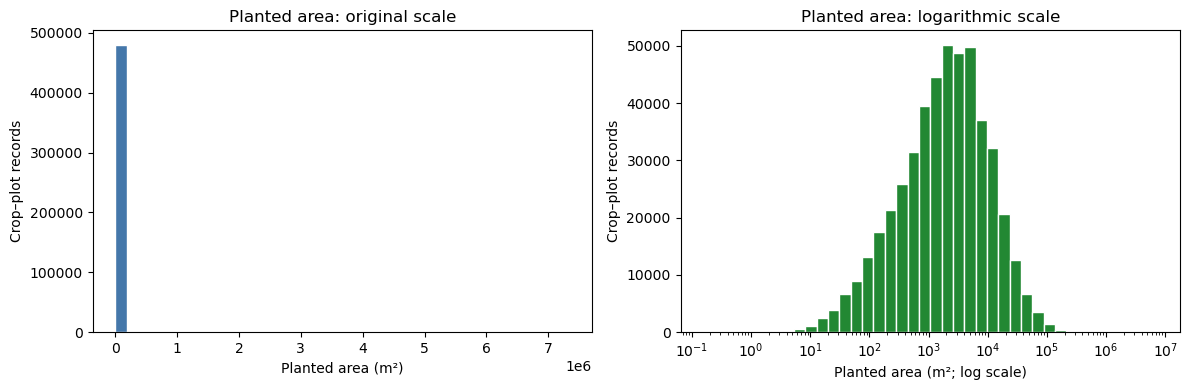

In [9]:
# These imports are needed in notebook 02 independently of notebook 01.
import matplotlib.pyplot as plt
import numpy as np

# Use the renamed area column from the crop–plot source table.
# Missing values are excluded from the chart only.
areas = crops["planted_area_m2"].dropna()

# A logarithmic axis requires positive values.
assert areas.gt(0).all(), "The logarithmic chart requires positive areas."

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Original scale: equal-width area intervals.
axes[0].hist(
    areas,
    bins=40,
    color="#4477AA",
    edgecolor="white"
)

axes[0].set(
    title="Planted area: original scale",
    xlabel="Planted area (m²)",
    ylabel="Crop–plot records"
)

# Create 40 intervals spaced evenly along a logarithmic axis.
log_bins = np.geomspace(areas.min(), areas.max(), 41)

axes[1].hist(
    areas,
    bins=log_bins,
    color="#228833",
    edgecolor="white"
)

axes[1].set_xscale("log")

axes[1].set(
    title="Planted area: logarithmic scale",
    xlabel="Planted area (m²; log scale)",
    ylabel="Crop–plot records"
)

plt.tight_layout()
plt.show()

Planted area has a long right tail: most observations are much smaller than a few very large areas. The logarithmic view makes the distribution across different area sizes easier to see.

Large observations remain included. These charts describe the crop-plot source table before aggregation to household–crop level.

### 4. Aggregate and join the tables

The harvest table defines the observations for modelling: one row per household–crop combination.

I first attach plot characteristics to the crop-plot records. I then aggregate these records to household–crop level before joining them to the harvest table. Finally, I attach household characteristics.

Each join is checked for unexpected duplication and unmatched records.

#### 4.1 Attach plot characteristics to crop records

A household can grow several crops on one plot. Each crop–plot record should therefore match one plot record, using household ID and plot ID together.

In [10]:
# Define the identifying columns for each source table.
PLOT_KEY = ["hhid", "plot_id"]

source_keys = {
    "Harvest": RECORD_KEY,
    "Households": ["hhid"],
    "Plots": PLOT_KEY,
    "Crops": ["hhid", "plot_id", "crop"]
}

# Confirm that every source has complete, unique identifying keys.
# An assertion stops execution if its condition is false.
for name, table in source_tables.items():
    keys = source_keys[name]

    assert not table[keys].isna().any().any(), (
        f"{name} contains missing key values."
    )

    assert not table.duplicated(keys).any(), (
        f"{name} contains duplicate keys."
    )

# Keep every crop–plot record and attach its plot characteristics.
crop_plots = crops.merge(
    plots,
    on=PLOT_KEY,
    how="left",
    validate="many_to_one",
    indicator="plot_match"
)

# The join must preserve the crop table's row count.
assert len(crop_plots) == len(crops)

# Check that every crop–plot record found a matching plot.
display(crop_plots["plot_match"].value_counts())

assert crop_plots["plot_match"].eq("both").all(), (
    "Some crop records did not match a plot."
)

# Remove the temporary matching-status column after checking it.
crop_plots = crop_plots.drop(columns="plot_match")

display(crop_plots.head())

plot_match
both          480393
left_only          0
right_only         0
Name: count, dtype: int64

,hhid,plot_id,crop,planted_area_m2,land_tenure,irrigation_infrastructure
0,326074.0,1.0,MAIZE,1123.600000,Owned by a member of the HH,NO
1,326074.0,2.0,RICE,2354.900000,Owned by a member of the HH,NO
2,326074.0,3.0,GUINEA CORN/SORGHUM,1125.900000,Owned by a member of the HH,NO
3,342175.0,1.0,RICE,11235.000000,Rented from somebody else (out of the HH),NO
4,274109.0,1.0,GUINEA CORN/SORGHUM,10373.999784,Owned by a member of the HH,NO


All 480,393 crop–plot records matched a plot record without increasing the number of observations.

#### 4.2 Summarise crop-plot records to household-crop level

For each household and crop, I calculate:

- Total reported planted area across plots.
- Number of distinct plots growing that crop.
- Proportion of those plots owned by household members.
- Proportion of those plots with irrigation infrastructure.

The proportions give each plot equal weight; they are not area-weighted.
The ownership measure summarises owned versus other tenure arrangements, so it does not preserve distinctions between renting and other forms of use.

In [11]:
# Check the values before converting irrigation responses into numbers.
# This prevents unexpected responses from silently becoming missing values.
assert crop_plots["irrigation_infrastructure"].isin(["YES", "NO"]).all()

# A missing tenure response must not accidentally be counted as "not owned".
assert crop_plots["land_tenure"].notna().all()

# Confirm that area values are present and positive before summing them.
assert crop_plots["planted_area_m2"].notna().all()
assert crop_plots["planted_area_m2"].gt(0).all()

# Represent infrastructure presence as 1 and absence as 0.
crop_plots["has_irrigation_infrastructure"] = (
    crop_plots["irrigation_infrastructure"]
    .map({"YES": 1, "NO": 0})
    .astype("Int64")
)

# Represent household ownership as 1 and other tenure arrangements as 0.
crop_plots["is_household_owned"] = (
    crop_plots["land_tenure"]
    .eq("Owned by a member of the HH")
    .astype("Int64")
)

# Combine all plots belonging to the same household-crop combination.
# observed=True avoids generating combinations of categories that never occur.
crop_features = (
    crop_plots
    .groupby(RECORD_KEY, observed=True, dropna=False)
    .agg(
        # Add the crop’s planted areas
        crop_planted_area_m2=("planted_area_m2", "sum"),
        # Count distinct plots growing the crop
        crop_plot_count=("plot_id", "nunique"),
        # Proportion of plots owned by household members
        owned_plot_share=("is_household_owned", "mean"),
        # Proportion of plots with irrigation infrastructure
        irrigation_infrastructure_share=(
            "has_irrigation_infrastructure", "mean" 
        )
    )
    .reset_index()
)

# Aggregation should produce one record per household–crop combination.
assert not crop_features.duplicated(RECORD_KEY).any()

print("Household-crop summaries:", f"{len(crop_features):,}")
display(crop_features.head())

Household-crop summaries: 433,015


,hhid,crop,crop_planted_area_m2,crop_plot_count,owned_plot_share,irrigation_infrastructure_share
0,1001.0,BEANS/COWPEA,420.240,1,1.0,0.0
1,1001.0,GROUND NUT/PEANUTS,280.160,1,1.0,0.0
2,1001.0,MILLET/MAIWA,700.400,1,1.0,0.0
3,1002.0,BEANS/COWPEA,262.665,1,1.0,0.0
4,1002.0,GUINEA CORN/SORGHUM,437.775,1,1.0,0.0


Aggregation produced 433,015 household-crop summaries.

These summaries cover a broader set of household-crop combinations than the harvest table. The modelling table will retain only the combinations with a reported-loss outcome in the harvest table.

#### 4.3 Attach the summaries and household characteristics

I use the harvest table as the left-hand table so that its observations define the modelling dataset.

Each harvest record should match one household-crop summary. Several harvest records may then match the same household record because a household can report several crops.

In [12]:
# Attach the aggregated crop/farm information to each harvest record.
# Both tables must contain unique household-crop keys.
model_data = harvest.merge(
    crop_features,
    on=RECORD_KEY,
    how="left",
    validate="one_to_one",
    indicator="crop_match"
)

display(model_data["crop_match"].value_counts())

assert len(model_data) == len(harvest)
assert model_data["crop_match"].eq("both").all(), (
    "Some harvest records did not match a crop summary."
)

model_data = model_data.drop(columns="crop_match")

# Attach household characteristics.
# Different crops from the same household receive the same household values.
model_data = model_data.merge(
    households,
    on="hhid",
    how="left",
    validate="many_to_one",
    indicator="household_match"
)

display(model_data["household_match"].value_counts())

assert model_data["household_match"].eq("both").all(), (
    "Some harvest records did not match a household."
)

model_data = model_data.drop(columns="household_match")

# Confirm that joining preserved the intended number and identity of records.
assert len(model_data) == len(harvest)
assert not model_data.duplicated(RECORD_KEY).any()

print("Modelling-table shape:", model_data.shape)
display(model_data.head())

crop_match
both          334133
left_only          0
right_only         0
Name: count, dtype: int64

household_match
both          334133
left_only          0
right_only         0
Name: count, dtype: int64

Modelling-table shape: (334133, 13)


,hhid,zone,state,sector,survey_weight,crop,reported_loss,crop_planted_area_m2,crop_plot_count,owned_plot_share,irrigation_infrastructure_share,farm_recordkeeping,listed_plot_count
0,326074.0,1.0,NASARAWA,URBAN,43.316891,RICE,No,2354.900000,1,1.0,0.0,PARTIALLY,3.0
1,342175.0,1.0,PLATEAU,RURAL,185.124704,RICE,No,11235.000000,1,0.0,0.0,"NO, NEVER",5.0
2,274109.0,3.0,KEBBI,URBAN,153.188059,GUINEA CORN/SORGHUM,No,17783.999629,2,1.0,0.0,OCCASIONALLY,2.0
3,347050.0,2.0,TARABA,RURAL,89.243114,BEANS/COWPEA,No,3518.080000,1,1.0,0.0,"NO, NEVER",2.0
4,545170.0,4.0,ANAMBRA,URBAN,390.568099,MELON/EGUSI,No,112.000000,1,1.0,0.0,"NO, NEVER",5.0


In [13]:
# Check missingness in the joined population.
# This can differ from missingness in the larger source tables.
print("Missing values after joining:")
display(model_data.isna().sum().to_frame("missing_records"))

# Confirm that the joins preserved the target distribution.
print("\nReported-loss responses:")
display(model_data[TARGET].value_counts(dropna=False))

assert model_data[TARGET].value_counts(dropna=False).equals(
    harvest[TARGET].value_counts(dropna=False)
), "The target distribution changed during joining."

Missing values after joining:


,missing_records
hhid,0
zone,0
state,0
sector,0
survey_weight,0
crop,0
reported_loss,0
crop_planted_area_m2,0
crop_plot_count,0
owned_plot_share,0



Reported-loss responses:


reported_loss
No     295686
Yes     38447
Name: count, dtype: int64

The joined modelling table contains 334,133 household-crop records and 13 columns. Every harvest record matched both a crop summary and a household record. No harvest records were lost or duplicated.

The reported-loss distribution remains unchanged: 295,686 records report no loss and 38,447 report loss.

No fields are missing in the joined table. Although the household source contains missing listing plot counts, none belong to households included in this harvest subset. No imputation was performed.

The new farm features describe crop-specific planted area, plot count, ownership share, and irrigation-infrastructure share. The shares are equally weighted across plots and do not represent shares of land area.

The modelling population remains the household-crop combinations represented in the harvest table, rather than all combinations in the crop source.

### 5. Validate and save the modelling table

Before saving, I check the columns, identifying keys, missing values, target responses, and calculated feature ranges.

The saved table will be the input to notebook 3. Identifiers and the survey weight stay separate from the model predictors.

In [14]:
# Add the prepared household and farm characteristics to the initial predictors.
ADDITIONAL_PREDICTORS = [
    "farm_recordkeeping",
    "listed_plot_count",
    "crop_planted_area_m2",
    "crop_plot_count",
    "owned_plot_share",
    "irrigation_infrastructure_share"
]

PREDICTORS = BASELINE_PREDICTORS + ADDITIONAL_PREDICTORS

print("Number of predictors:", len(PREDICTORS))
print(PREDICTORS)

Number of predictors: 10
['zone', 'state', 'sector', 'crop', 'farm_recordkeeping', 'listed_plot_count', 'crop_planted_area_m2', 'crop_plot_count', 'owned_plot_share', 'irrigation_infrastructure_share']


In [15]:
# Check that the table contains exactly the intended fields.
expected_columns = set(
  PREDICTORS + [GROUP_COLUMN, TARGET, WEIGHT_COLUMN]
)

assert set(model_data.columns) == expected_columns, (
  "The modelling table has missing or unexpected columns."
)

# Confirm that every original harvest record is still represented once.
assert len(model_data) == len(harvest)
assert not model_data.duplicated(RECORD_KEY).any()

# Our earlier joins produced no missing values.
# Stop if the current result differs, rather than filling values automatically.
assert not model_data.isna().any().any(), (
  "The modelling table contains missing values."
)

# Confirm that the target contains only the expected responses.
assert model_data[TARGET].isin(["Yes", "No"]).all()

# Check the basic ranges of the numeric fields.
assert model_data["listed_plot_count"].ge(0).all()
assert model_data["crop_planted_area_m2"].gt(0).all()
assert model_data["crop_plot_count"].ge(1).all()
assert model_data[WEIGHT_COLUMN].gt(0).all()

# Both plot-share features must lie between zero and one.
for column in ["owned_plot_share", "irrigation_infrastructure_share"]:
  assert model_data[column].between(0, 1).all(), (
    f"{column} contains values outside zero to one."
  )

print("Validation checks passed.")
print("Table shape:", model_data.shape)

display(model_data[TARGET].value_counts(dropna=False))

Validation checks passed.
Table shape: (334133, 13)


reported_loss
No     295686
Yes     38447
Name: count, dtype: int64

#### Save the prepared data

Save the validated table as a CSV file in `data/processed`. This gives notebook 03 a single, reproducible input file.

CSV preserves the values but does not retain pandas categorical data types. The categorical predictors will be identified explicitly in notebook 03.

In [16]:
# Create the output directory if it does not already exist.
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "modelling_data.csv"

# Save the table without adding the DataFrame's row index as an extra column.
# Rerunning this line replaces the generated CSV.
model_data.to_csv(OUTPUT_FILE, index=False)

print("Saved:", OUTPUT_FILE.resolve())

# Read the saved file back to check its basic structure.
saved_data = pd.read_csv(OUTPUT_FILE)

assert saved_data.shape == model_data.shape
assert saved_data.columns.tolist() == model_data.columns.tolist()
assert not saved_data.duplicated(RECORD_KEY).any()

# Compare response counts using dictionaries to avoid categorical-type differences.
assert saved_data[TARGET].value_counts().to_dict() == (
    model_data[TARGET].value_counts().to_dict()
)

print("Saved-file checks passed.")

Saved: /Users/mac/Developer/HIS/Courses/Introduction to Data Science A1N/Assignments/nass-postharvest-project/data/processed/modelling_data.csv
Saved-file checks passed.


The modelling table passed the column, key, missing-value, target, and numeric-range checks.

The saved CSV contains 334,133 records and 13 columns. Its dimensions, column names, key uniqueness, and target counts were confirmed after reading it back.

### 6. Preparation summary

The prepared dataset contains one row per household–crop record. It combines the reported-loss target with ten candidate predictors.

Plot and crop information was aggregated before joining. All harvest records were retained, with no duplicate household–crop keys.

No missing-value imputation or outlier removal was applied. Large planted areas remain documented for later assessment.

The prepared table is saved as `data/processed/modelling_data.csv`.

Notebook 03 will split records by household, build modelling pipelines, compare models, and evaluate their predictions.